# Modelo Multimodal

Um modelo Multimodal é um sistema capaz de processar e combinar múltiplos **formatos** de informações, como: texto, imagens, áudio e vídeo.

A ideia por trás desse conceito é utilizar todos os dados disponíveis para que o modelo tenha uma visão mais completa do problema e o treinamento seja mais eficiente.

## 1. O primeiro teste será juntando os dados das imagens com os dados tabulares

### 1.1. Setup do ambiente

In [1]:
!pip install github-content-downloader

import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import nltk
import pandas as pd
import seaborn as sns
import shutil
import tensorflow as tf

from github_downloader import download_from_github
from google.colab import files

from nltk.tokenize import word_tokenize
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Baixar pacotes necessários do NLTK
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

### 1.2. Baixar os dados brutos

In [5]:
# Definir diretório de imagens padrão se não definido
images_dir = globals().get('images_dir', '/content/data/raw/images')
os.makedirs(images_dir, exist_ok=True)

# Definir caminhos
raw_data_path = (
    'https://raw.githubusercontent.com/'
    'especializacao-ia-pucsp/'
    'grupo-01-projeto_supervisionado-II/'
    'refs/heads/main/data/raw/chamados.csv'
)
preprocessed_dir = '/content/data/preprocessed'
os.makedirs(preprocessed_dir, exist_ok=True)

### 1.2 Carregar dados brutos
print("Lendo o dataset bruto...")
df = pd.read_csv(raw_data_path)
download_from_github(
    (
        "https://github.com/"
        "especializacao-ia-pucsp/"
        "grupo-01-projeto_supervisionado-II/"
        "tree/main/data/raw/images"
    ),
    dest_folder=images_dir
)

### Encodar os Rótulos
le = LabelEncoder()
le.fit_transform(df['target_category'])

### Estruturar caminhos e pré-processar as Imagens brutas
print("Processando imagens físicas para a model_vision...")
if 'image_path' in df.columns:
    df['full_image_path'] = df['image_path'].apply(lambda x: os.path.join(images_dir, os.path.basename(str(x))))
else:
    df['full_image_path'] = ''

image_arrays = []
for idx, img_path in enumerate(df['full_image_path']):
    try:
        img = load_img(img_path, target_size=(224, 224))
        img_arr = img_to_array(img)
        img_preprocessed = preprocess_input(img_arr)
        image_arrays.append(img_preprocessed)
    except Exception as e:
        # Fallback de imagem em branco caso haja falha de carregamento ou arquivo ausente
        image_arrays.append(np.zeros((224, 224, 3)))

images_preprocessed = np.array(image_arrays)


Lendo o dataset bruto...
Downloaded: /content/data/raw/images/access_denied.png
Downloaded: /content/data/raw/images/browser.png
Downloaded: /content/data/raw/images/cooler.png
Downloaded: /content/data/raw/images/default_access.png
Downloaded: /content/data/raw/images/default_finance.png
Downloaded: /content/data/raw/images/default_hardware.png
Downloaded: /content/data/raw/images/default_hr.png
Downloaded: /content/data/raw/images/default_network.png
Downloaded: /content/data/raw/images/default_software.png
Downloaded: /content/data/raw/images/email.png
Downloaded: /content/data/raw/images/finance_report.png
Downloaded: /content/data/raw/images/hard_drive.png
Downloaded: /content/data/raw/images/hr_portal.png
Downloaded: /content/data/raw/images/keyboard.png
Downloaded: /content/data/raw/images/login.png
Downloaded: /content/data/raw/images/monitor.png
Downloaded: /content/data/raw/images/motherboard.png
Downloaded: /content/data/raw/images/mouse.png
Downloaded: /content/data/raw/ima

### 1.3. Pré-processamento dos Dados Tabulares

Como o modelo necessita de entradas numéricas para a parte tabular, precisamos selecionar as colunas de interesse do `df`, realizar o tratamento/codificação e gerar as variáveis `X_tab_treino_processed`, `X_tab_val_processed` e `X_tab_teste_processed` de acordo com os índices de divisão correspondentes.

In [24]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Identificar colunas do dataframe que usaremos como features tabulares
colunas_categoricas = [
    'department',
    'city_x',
    'state_x',
    'device_type',
    'os',
    'browser',
    'network_type',
    'priority',
    'status',
    'assigned_team'
]
colunas_numericas = [
    'historical_tickets',
    'sla_hours',
    'resolution_time_hours',
    'image_width',
    'image_height',
    'sentiment_score',
    'num_words',
    'num_images_x',
    'latitude',
    'longitude'
]

# 2. Criar pipelines de pré-processamento
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, colunas_numericas),
        ('cat', categorical_transformer, colunas_categoricas)
    ]
)

# 3. Separar as features brutas usando os índices já definidos
X_raw = df[colunas_numericas + colunas_categoricas]

# 4. Ajustar e transformar nos conjuntos correspondentes para popular as variáveis
# Ajustamos o preprocessor APENAS no treino para evitar vazamento de dados (data leakage)
X_tab_treino_processed = preprocessor.fit_transform(X_raw.iloc[idx_treino])
X_tab_val_processed = preprocessor.transform(X_raw.iloc[idx_val])
X_tab_teste_processed = preprocessor.transform(X_raw.iloc[idx_teste])

print(f"Shape de treino processado: {X_tab_treino_processed.shape}")
print(f"Shape de validação processado: {X_tab_val_processed.shape}")
print(f"Shape de teste processado: {X_tab_teste_processed.shape}")

Shape de treino processado: (4000, 51)
Shape de validação processado: (500, 51)
Shape de teste processado: (500, 51)


## 2. Modelo com Visão Computacional e os dados Tabulares

O nosso modelo Multimodal utiliza o MobileNetV2 para a parte de visão computacional, enquanto a rede MLP para a parte textual (tabular) usa 51 características diferentes para cada ticket.

In [25]:
# Função geradora de duas entradas (Imagem + Tabular) corrigida usando tuplas
def multimodal_generator(indices, batch_size=32, shuffle=True):
    num_samples = len(indices)
    while True:
        if shuffle:
            np.random.shuffle(indices)
        for offset in range(0, num_samples, batch_size):
            batch_indices = indices[offset:offset+batch_size]
            batch_images = []
            batch_tabular = []
            batch_labels = []

            for idx in batch_indices:
                img_path = df.loc[idx, 'full_image_path']
                label = y[idx]

                # Obter vetor tabular adequado com base no conjunto (treino, val ou teste)
                if idx in idx_treino:
                    pos = np.where(idx_treino == idx)[0][0]
                    tab_feat = X_tab_treino_processed[pos]
                elif idx in idx_val:
                    pos = np.where(idx_val == idx)[0][0]
                    tab_feat = X_tab_val_processed[pos]
                else:
                    pos = np.where(idx_teste == idx)[0][0]
                    tab_feat = X_tab_teste_processed[pos]

                # Carregar Imagem
                try:
                    img = load_img(img_path, target_size=(224, 224))
                    img_array = img_to_array(img)
                    img_preprocessed = preprocess_input(img_array)
                    batch_images.append(img_preprocessed)
                except Exception:
                    batch_images.append(np.zeros((224, 224, 3)))

                batch_tabular.append(tab_feat)
                batch_labels.append(label)

            # Retornar uma tupla contendo outra tupla com os inputs, e o label
            yield (np.array(batch_images), np.array(batch_tabular)), np.array(batch_labels)

# Instanciar os geradores multimodais corrigidos
train_multi_gen = multimodal_generator(idx_treino, batch_size=32, shuffle=True)
val_multi_gen = multimodal_generator(idx_val, batch_size=32, shuffle=False)
test_multi_gen = multimodal_generator(idx_teste, batch_size=32, shuffle=False)

Define os dois ramos de processamento e a fusão dos dados no final

In [26]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Definir a dimensão de entrada dos dados tabulares
tabular_input_dim = X_tab_treino_processed.shape[1]

# 1. Ramo de Imagem (MobileNetV2)
image_input = layers.Input(shape=(224, 224, 3), name='image_input')
base_mobilenet = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_mobilenet.trainable = False

x_img = base_mobilenet(image_input)
x_img = layers.GlobalAveragePooling2D()(x_img)
x_img = layers.Dense(128, activation='relu')(x_img)

# 2. Ramo Tabular
tabular_input = layers.Input(shape=(tabular_input_dim,), name='tabular_input')
x_tab = layers.Dense(64, activation='relu')(tabular_input)
x_tab = layers.Dropout(0.2)(x_tab)

# Concatenação
combined = layers.concatenate([x_img, x_tab])

# Camadas densas finais de classificação
x = layers.Dense(128, activation='relu')(combined)
x = layers.Dropout(0.3)(x)
output = layers.Dense(len(le.classes_), activation='softmax')(x)

# Criar e compilar o modelo de duas entradas
model_multimodal = models.Model(inputs=[image_input, tabular_input], outputs=output)
model_multimodal.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_multimodal.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ image_input[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tabular_input       │ (None, 51)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │      3,328 │ tabular_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │    163,968 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 192)       │          0 │ dense_4[0][0],    │
│ (Concatenate)       │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │     24,704 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 6)         │        774 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,450,758 (9.35 MB)

 Trainable params: 192,774 (753.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [28]:
# Definir tamanho do batch padrão usado nos geradores
batch_size = 32

# Calcular os passos por época para cada conjunto
spe_train = len(idx_treino) // batch_size
spe_val = len(idx_val) // batch_size
spe_test = len(idx_teste) // batch_size

print("Treinando o modelo Multimodal (Imagens + Dados Tabulares)...")
history_multi = model_multimodal.fit(
    train_multi_gen,
    steps_per_epoch=spe_train,
    validation_data=val_multi_gen,
    validation_steps=spe_val,
    epochs=5
)

# Avaliar modelo
print("\nAvaliando o modelo Multimodal no conjunto de teste...")
test_loss, test_acc = model_multimodal.evaluate(test_multi_gen, steps=spe_test)
print(f"\nAcurácia final do Modelo Multimodal: {test_acc:.4f}")

Treinando o modelo Multimodal (Imagens + Dados Tabulares)...
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 57s 292ms/step - accuracy: 0.7803 - loss: 0.6370 - val_accuracy: 0.8021 - val_loss: 0.4992
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 32s 254ms/step - accuracy: 0.8025 - loss: 0.5292 - val_accuracy: 0.8208 - val_loss: 0.4863
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 31s 249ms/step - accuracy: 0.8133 - loss: 0.5079 - val_accuracy: 0.8292 - val_loss: 0.4802
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 38s 302ms/step - accuracy: 0.8108 - loss: 0.5068 - val_accuracy: 0.8098 - val_loss: 0.4727
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 228ms/step - accuracy: 0.8158 - loss: 0.4970 - val_accuracy: 0.8292 - val_loss: 0.4597

Avaliando o modelo Multimodal no conjunto de teste...
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 214ms/step - accuracy: 0.8417 - loss: 0.4195

Acurcia final do Modelo Multimodal: 0.8417


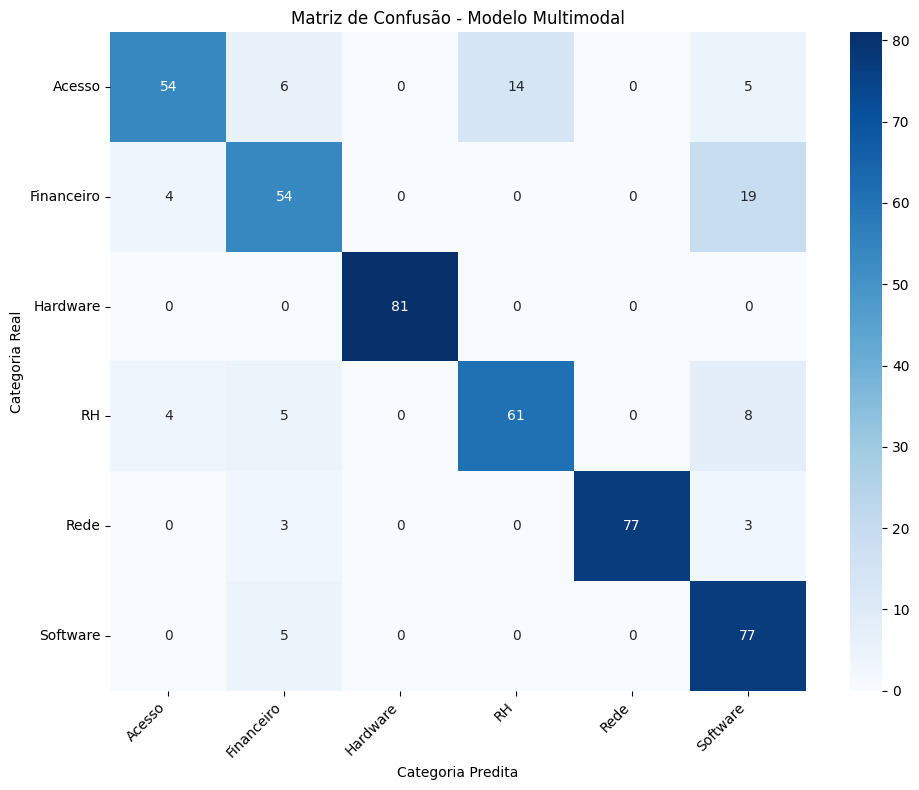

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Obter predições e rótulos reais do gerador de teste
# Iteramos exatamente a quantidade correta de passos do conjunto de teste para garantir o alinhamento completo
y_true = []
y_pred = []

# Reiniciar o gerador de teste criando uma instância nova para evitar problemas com offsets
test_gen_evaluation = multimodal_generator(idx_teste, batch_size=32, shuffle=False)

for i in range(spe_test):
    (batch_img, batch_tab), batch_labels = next(test_gen_evaluation)
    preds = model_multimodal.predict((batch_img, batch_tab), verbose=0)

    y_true.extend(batch_labels)
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Calcular a matriz de confusão
cm = confusion_matrix(y_true, y_pred)
class_names = le.classes_

# 3. Plotar a matriz usando seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matriz de Confusão - Modelo Multimodal')
plt.ylabel('Categoria Real')
plt.xlabel('Categoria Predita')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 1.4. Modelo Exclusivamente Tabular
Para fins de comparação com o modelo multimodal, vamos construir uma arquitetura de rede neural densa (MLP) utilizando apenas as nossas features tabulares processadas.

In [44]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Definir as dimensões de entrada dos dados tabulares
input_dim = X_tab_treino_processed.shape[1]
num_classes = len(le.classes_)

# Construir a arquitetura da Rede Neural Tabular
model_tabular = models.Sequential([
    layers.Input(shape=(tabular_input_dim,)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(le.classes_), activation='softmax')
])

# Compilar o modelo
model_tabular.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_tabular.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 64)             │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,422 (48.52 KB)

 Trainable params: 12,422 (48.52 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
# Extrair rótulos correspondentes para treino, validação e teste
y_treino = y[idx_treino]
y_val = y[idx_val]
y_teste = y[idx_teste]

# Treinar o modelo exclusivamente tabular
print("Treinando o modelo exclusivamente Tabular...")
history_tab = model_tabular.fit(
    X_tab_treino_processed,
    y_treino,
    validation_data=(X_tab_val_processed, y_val),
    epochs=5,
    batch_size=32
)

# Avaliar o modelo tabular no conjunto de teste
print("\nAvaliando o modelo Tabular no conjunto de teste...")
test_loss_tab, test_acc_tab = model_tabular.evaluate(X_tab_teste_processed, y_teste, verbose=1)
print(f"\nAcurácia final do Modelo Tabular: {test_acc_tab:.4f}")

Treinando o modelo exclusivamente Tabular...
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.1745 - loss: 1.8310 - val_accuracy: 0.1500 - val_loss: 1.8041
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1842 - loss: 1.7974 - val_accuracy: 0.1380 - val_loss: 1.8097
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2000 - loss: 1.7844 - val_accuracy: 0.1440 - val_loss: 1.8069
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2153 - loss: 1.7756 - val_accuracy: 0.1580 - val_loss: 1.8100
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2320 - loss: 1.7711 - val_accuracy: 0.1500 - val_loss: 1.8125

Avaliando o modelo Tabular no conjunto de teste...
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1480 - loss: 1.8069 

Acurácia final do Modelo Tabular: 0.1480


### 1.5. Otimização do Modelo Tabular
Vamos aplicar técnicas avançadas como aumento de capacidade da rede, ajuste de taxa de aprendizado (Learning Rate) e Early Stopping para tentar elevar a acurácia dos dados estruturados.

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# 1. Definir a arquitetura otimizada
model_tabular_opt = models.Sequential([
    layers.Input(shape=(X_tab_treino_processed.shape[1],)),

    layers.Dense(256, activation='swish'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    layers.Dense(128, activation='swish'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(64, activation='swish'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Dense(len(le.classes_), activation='softmax')
])

# 2. Compilar com uma taxa de aprendizado customizada (menor)
optimizer_opt = tf.keras.optimizers.Adam(learning_rate=0.0005)
model_tabular_opt.compile(
    optimizer=optimizer_opt,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Adicionar Callbacks para evitar overfitting e salvar o melhor modelo
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

# 4. Treinar o modelo por mais épocas
print("Treinando o modelo Tabular Otimizado...")
history_tab_opt = model_tabular_opt.fit(
    X_tab_treino_processed,
    y_treino,
    validation_data=(X_tab_val_processed, y_val),
    epochs=40,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# 5. Avaliar no conjunto de teste
test_loss_opt, test_acc_opt = model_tabular_opt.evaluate(X_tab_teste_processed, y_teste, verbose=0)
print(f"\nAcurácia do Modelo Tabular Inicial: {test_acc_tab:.4f}")
print(f"Acurácia do Modelo Tabular Otimizado: {test_acc_opt:.4f}")

Treinando o modelo Tabular Otimizado...
Epoch 1/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 24s 180ms/step - accuracy: 0.1748 - loss: 2.4211 - val_accuracy: 0.1420 - val_loss: 1.8069
Epoch 2/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1690 - loss: 2.2410 - val_accuracy: 0.1520 - val_loss: 1.8147
Epoch 3/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1832 - loss: 2.1142 - val_accuracy: 0.1520 - val_loss: 1.8197
Epoch 4/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1830 - loss: 2.0496 - val_accuracy: 0.1360 - val_loss: 1.8290
Epoch 5/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1935 - loss: 1.9854 - val_accuracy: 0.1420 - val_loss: 1.8341
Epoch 6/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1857 - loss: 1.9823 - val_accuracy: 0.1400 - val_loss: 1.8494
Epoch 7/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1905 - loss: 1.9292 - val_accuracy: 0.1300 - val_loss: 1.8606
Epoch 8/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2025 - loss

### 1.7. Modelo Baseado Exclusivamente em Imagens (Visão Computacional)
Vamos construir uma arquitetura de classificação de imagens pura utilizando o MobileNetV2 pré-treinado como extrator de características para isolar a performance preditiva dos dados visuais.

In [33]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# 1. Obter os arrays de imagens correspondentes de acordo com os índices de divisão
X_img_treino = images_preprocessed[idx_treino]
X_img_val = images_preprocessed[idx_val]
X_img_teste = images_preprocessed[idx_teste]

# 2. Definir a arquitetura baseada no MobileNetV2
base_mobilenet_pure = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_mobilenet_pure.trainable = False

model_vision = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_mobilenet_pure,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(le.classes_), activation='softmax')
])

# 3. Compilar o modelo de visão pura
model_vision.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_vision.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [34]:
# 4. Treinar o modelo exclusivamente de imagens
print("Treinando o modelo de Visão Computacional Pura...")
history_vision = model_vision.fit(
    X_img_treino,
    y_treino,
    validation_data=(X_img_val, y_val),
    epochs=5,
    batch_size=32
)

# 5. Avaliar o desempenho no conjunto de teste
print("\nAvaliando o modelo de Visão Computacional no conjunto de teste...")
test_loss_vision, test_acc_vision = model_vision.evaluate(X_img_teste, y_teste, verbose=1)
print(f"\nAcurácia final do Modelo de Imagens: {test_acc_vision:.4f}")

Treinando o modelo de Visão Computacional Pura...
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 81ms/step - accuracy: 0.7755 - loss: 0.6528 - val_accuracy: 0.8020 - val_loss: 0.5065
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8080 - loss: 0.5179 - val_accuracy: 0.8260 - val_loss: 0.4812
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8108 - loss: 0.5129 - val_accuracy: 0.8020 - val_loss: 0.4756
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.8098 - loss: 0.5100 - val_accuracy: 0.8140 - val_loss: 0.4669
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8135 - loss: 0.4990 - val_accuracy: 0.8260 - val_loss: 0.4700

Avaliando o modelo de Visão Computacional no conjunto de teste...
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8420 - loss: 0.4043

Acurácia final do Modelo de Imagens: 0.8420
